Supply Chain (demand)            R2 train=0.582  R2 test=0.595  RMSE=50.11  MAE=39.55
BFSI (card spend)                R2 train=0.759  R2 test=0.756  RMSE=4959.58  MAE=3947.01
AdTech (revenue per user)        R2 train=0.947  R2 test=0.945  RMSE=30.19  MAE=23.9
Telecom (monthly bill)           R2 train=0.973  R2 test=0.973  RMSE=19.97  MAE=15.84
Cybersecurity (latency)          R2 train=0.878  R2 test=0.884  RMSE=4.95  MAE=3.95
IT Infrastructure (CPU usage)    R2 train=0.924  R2 test=0.924  RMSE=5.08  MAE=4.03
Healthcare (risk score)          R2 train=0.787  R2 test=0.773  RMSE=10.31  MAE=8.3
HR (salary)                      R2 train=0.983  R2 test=0.983  RMSE=2979.58  MAE=2401.42
Civil (concrete strength)        R2 train=0.973  R2 test=0.973  RMSE=10.03  MAE=7.96
Energy (energy usage)            R2 train=0.884  R2 test=0.887  RMSE=9.97  MAE=7.88
EdTech (final score)             R2 train=0.955  R2 test=0.953  RMSE=5.05  MAE=4.02
Automotive (mileage)             R2 train=0.772  R2 test=0

/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: i

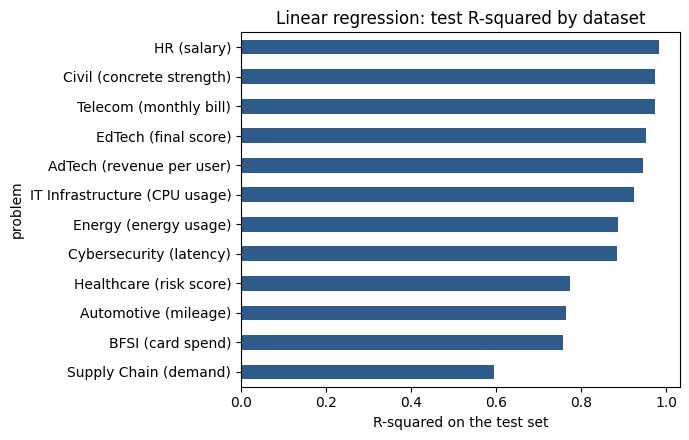

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

DATA = "../data/Regression_datasets"
OUT = "../output"
os.makedirs(OUT, exist_ok=True)

# file name -> what we predict (the last column of every file is the target y)
problems = {
    "supply_chain": "Supply Chain (demand)",
    "bfsi": "BFSI (card spend)",
    "adtech": "AdTech (revenue per user)",
    "telecom": "Telecom (monthly bill)",
    "cybersecurity": "Cybersecurity (latency)",
    "it_infra": "IT Infrastructure (CPU usage)",
    "healthcare": "Healthcare (risk score)",
    "hr": "HR (salary)",
    "civil": "Civil (concrete strength)",
    "energy": "Energy (energy usage)",
    "edtech": "EdTech (final score)",
    "automotive": "Automotive (mileage)",
}

rows, coef_rows = [], []
for file, title in problems.items():
    df = pd.read_csv(f"{DATA}/{file}.csv")
    target = df.columns[-1]
    y = df[target]
    X = df.drop(columns=[target])

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42)

    # no scaling needed for plain linear regression: predictions are the same,
    # and the coefficients stay in the original units (easy to explain)
    model = LinearRegression()
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    rows.append({
        "problem": title, "target": target,
        "r2_train": round(model.score(X_train, y_train), 3),
        "r2_test": round(r2_score(y_test, pred), 3),
        "rmse": round(np.sqrt(mean_squared_error(y_test, pred)), 2),
        "mae": round(mean_absolute_error(y_test, pred), 2),
        "target_mean": round(y.mean(), 1),
    })
    for name, c in zip(X.columns, model.coef_):
        coef_rows.append({"problem": title, "feature": name, "coefficient": round(c, 3)})
    coef_rows.append({"problem": title, "feature": "intercept", "coefficient": round(model.intercept_, 3)})

    print(f"{title:32s} R2 train={rows[-1]['r2_train']}  R2 test={rows[-1]['r2_test']}  "
          f"RMSE={rows[-1]['rmse']}  MAE={rows[-1]['mae']}")

results = pd.DataFrame(rows)
results.to_csv(f"{OUT}/linear_results.csv", index=False)
pd.DataFrame(coef_rows).to_csv(f"{OUT}/linear_coefficients.csv", index=False)

# chart: how much of the variation does each model explain?
results.sort_values("r2_test").plot.barh(x="problem", y="r2_test", legend=False,
                                         color="#2E5B8A", figsize=(7, 4.5))
plt.xlabel("R-squared on the test set")
plt.title("Linear regression: test R-squared by dataset")
plt.tight_layout()
plt.savefig(f"{OUT}/linear_r2.png", dpi=110)